In [1]:
import pandas as pd
import numpy as np

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


1. Escolha os arquivos e escreva, em uma ou duas frases, uma pergunta de negócio que esses
dados poderiam responder. Ela vai orientar suas decisões de limpeza.

In [5]:
beleza = pd.read_csv('/content/drive/MyDrive/data science/us-shein-beauty_and_health-4267.csv')
eletronicos = pd.read_csv('/content/drive/MyDrive/data science/us-shein-electronics-4395.csv')

In [6]:
display(beleza.head())

,goods-title-link--jump,goods-title-link--jump href,selling_proposition,price,discount,color-count,rank-title,rank-sub,goods-title-link
0,90ML 3.0FL.OZ Fragrance Hair & Body Mist Vanil...,https://us.shein.com/90ML-3-0FL-OZ-Fragrance-H...,30+ sold recently,$5.90,-5%,NaN,NaN,NaN,NaN
1,SHEGLAM Color Bloom Liquid Blush Matte Finish-...,https://us.shein.com/SHEGLAM-Color-Bloom-Liqui...,NaN,$4.99,-17%,14.0,#2 Best Sellers,in Blush,NaN
2,1pc Silicone Facial Massage Ice Tray,https://us.shein.com/1pc-Silicone-Facial-Massa...,NaN,$2.64,-20%,NaN,#1 Best Sellers,in Facial Massage Tools,NaN
3,5Ml Bottom Refillable Perfume Bottle With Pump...,https://us.shein.com/5Ml-Bottom-Refillable-Per...,5.3k+ sold recently,$1.50,-12%,NaN,NaN,NaN,NaN
4,12pcs Multi-Functional Makeup Brush Set Includ...,https://us.shein.com/12pcs-Multi-Functional-Ma...,NaN,$7.80,-5%,8.0,#2 Best Sellers,in Brushes Sets,NaN


In [7]:
display(eletronicos.head())

,goods-title-link--jump,goods-title-link--jump href,rank-title,rank-sub,price,discount,selling_proposition,color-count,goods-title-link
0,10pcs Random Color Data Cable Organizer,https://us.shein.com/10pcs-Random-Color-Data-C...,#10 Best Sellers,in Cable Storage,$1.36,-20%,NaN,NaN,NaN
1,3pcs Anti Glare Tempered Glass Front Film Phon...,https://us.shein.com/3pcs-Anti-Glare-Tempered-...,#1 Best Sellers,in Screen Protectors,$2.32,-20%,NaN,NaN,NaN
2,"Universal Waterproof Phone Pouch, Waterproof P...",https://us.shein.com/Universal-Waterproof-Phon...,NaN,NaN,$1.70,NaN,600+ sold recently,NaN,NaN
3,"Silicone Phone Suction Cup, 24PCS Universal Su...",https://us.shein.com/Silicone-Phone-Suction-Cu...,#5 Best Sellers,in Adhesive Cardholders,$0.38,-71%,NaN,8.0,NaN
4,Customized Phone Case Compatible With Iphone 1...,https://us.shein.com/Customized-Phone-Case-Com...,#9 Best Sellers,in Customized Phone Cases,$3.10,NaN,NaN,7.0,NaN


**Pergunta de negócio:**

* Como a qualidade dos dados dos produtos das categorias de beleza e saúde e eletrônicos influencia a análise dos preços e a tomada de decisões comerciais?

A limpeza dos dados buscará identificar valores ausentes, registros duplicados, inconsistências e valores atípicos que possam comprometer a análise.

2. Faça o diagnóstico inicial e registre os problemas encontrados antes de corrigir qualquer coisa.

In [8]:
def diagnostico(dados, nome):
    print(f"\n===== {nome} =====")

    print("\nDimensões (linhas, colunas):")
    print(dados.shape)

    print("\nTipos de dados:")
    print(dados.dtypes)

    print("\nValores ausentes por coluna:")
    print(dados.isnull().sum())

    print("\nLinhas duplicadas:")
    print(dados.duplicated().sum())

    print("\nEstatísticas das colunas numéricas:")
    display(dados.describe())

diagnostico(beleza, "Beleza e saúde")
diagnostico(eletronicos, "Eletrônicos")


===== Beleza e saúde =====

Dimensões (linhas, colunas):
(4266, 9)

Tipos de dados:
goods-title-link--jump          object
goods-title-link--jump href     object
selling_proposition             object
price                           object
discount                        object
color-count                    float64
rank-title                      object
rank-sub                        object
goods-title-link                object
dtype: object

Valores ausentes por coluna:
goods-title-link--jump         4227
goods-title-link--jump href    4227
selling_proposition            1009
price                             0
discount                        282
color-count                    3060
rank-title                     3428
rank-sub                       3428
goods-title-link                 39
dtype: int64

Linhas duplicadas:
12

Estatísticas das colunas numéricas:


,color-count
count,1206.000000
mean,8.311774
std,5.619821
min,4.000000
25%,4.000000
50%,6.000000
75%,10.000000
max,36.000000



===== Eletrônicos =====

Dimensões (linhas, colunas):
(4394, 9)

Tipos de dados:
goods-title-link--jump          object
goods-title-link--jump href     object
rank-title                      object
rank-sub                        object
price                           object
discount                        object
selling_proposition             object
color-count                    float64
goods-title-link                object
dtype: object

Valores ausentes por coluna:
goods-title-link--jump         4356
goods-title-link--jump href    4356
rank-title                     3647
rank-sub                       3647
price                             0
discount                       2869
selling_proposition            1227
color-count                    3256
goods-title-link                 38
dtype: int64

Linhas duplicadas:
34

Estatísticas das colunas numéricas:


,color-count
count,1138.000000
mean,6.494728
std,3.578307
min,4.000000
25%,4.000000
50%,5.000000
75%,7.000000
max,31.000000


**Diagnóstico inicial dos dados**

Na base de beleza e saúde, foram identificados 4.266 registros, 9 colunas, 12 linhas duplicadas e valores ausentes em diversas colunas. Na base de eletrônicos, foram encontrados 4.394 registros, 9 colunas, 34 linhas duplicadas e também uma quantidade significativa de valores ausentes.

Além disso, a coluna de preços está armazenada como texto nas duas bases, sendo necessário verificar seu formato para possibilitar análises numéricas. Foram identificados possíveis problemas de qualidade relacionados a dados ausentes, duplicatas e tipos de dados. Nenhuma alteração foi realizada nesta etapa, pois o objetivo foi apenas diagnosticar e registrar os problemas encontrados.

3. Construa um pipeline de limpeza que trate, na ordem que você julgar adequada:

a) tipos de dados incorretos (por exemplo, preços ou descontos armazenados como texto);

In [9]:
print("Preços - beleza e saúde:")
display(beleza["price"].head(10))

print("Descontos - beleza e saúde:")
display(beleza["discount"].head(10))

print("Preços - eletrônicos:")
display(eletronicos["price"].head(10))

print("Descontos - eletrônicos:")
display(eletronicos["discount"].head(10))

Preços - beleza e saúde:


,price
0,$5.90
1,$4.99
2,$2.64
3,$1.50
4,$7.80
5,$2.60
6,$5.30
7,$5.66
8,$2.60
9,$0.15


Descontos - beleza e saúde:


,discount
0,-5%
1,-17%
2,-20%
3,-12%
4,-5%
5,-4%
6,-4%
7,-12%
8,-7%
9,-89%


Preços - eletrônicos:


,price
0,$1.36
1,$2.32
2,$1.70
3,$0.38
4,$3.10
5,$0.90
6,$9.80
7,$1.30
8,$1.60
9,$1.70


Descontos - eletrônicos:


,discount
0,-20%
1,-20%
2,NaN
3,-71%
4,NaN
5,-40%
6,-4%
7,NaN
8,NaN
9,NaN


In [10]:
# Criar cópias para preservar os dados originais
beleza_limpo = beleza.copy()
eletronicos_limpo = eletronicos.copy()

# Converter tipo de dado
for dados in [beleza_limpo, eletronicos_limpo]:
    dados["price"] = pd.to_numeric(
        dados["price"].str.replace("$", "", regex=False),
        errors="coerce"
    )

    dados["discount"] = pd.to_numeric(
        dados["discount"].str.replace("%", "", regex=False),
        errors="coerce"
    )

print("Tipos de beleza e saúde:")
print(beleza_limpo[["price", "discount"]].dtypes)

print("\nTipos de eletrônicos:")
print(eletronicos_limpo[["price", "discount"]].dtypes)


Tipos de beleza e saúde:
price       float64
discount    float64
dtype: object

Tipos de eletrônicos:
price       float64
discount    float64
dtype: object


b) valores ausentes;

In [12]:
print("Ausentes - beleza e saúde:")
display(beleza_limpo.isnull().sum())

print("Ausentes - eletrônicos:")
display(eletronicos_limpo.isnull().sum())

Ausentes - beleza e saúde:


,0
goods-title-link--jump,4227
goods-title-link--jump href,4227
selling_proposition,1009
price,0
discount,282
color-count,3060
rank-title,3428
rank-sub,3428
goods-title-link,39


Ausentes - eletrônicos:


,0
goods-title-link--jump,4356
goods-title-link--jump href,4356
rank-title,3647
rank-sub,3647
price,1
discount,2869
selling_proposition,1227
color-count,3256
goods-title-link,38


In [13]:
# Remover colunas com muitos valores ausentes
colunas_remover = [
    "goods-title-link--jump",
    "goods-title-link--jump href"
]

beleza_limpo = beleza_limpo.drop(columns=colunas_remover)
eletronicos_limpo = eletronicos_limpo.drop(columns=colunas_remover)

# Verificar os valores ausentes restantes
print("Beleza e saúde:")
display(beleza_limpo.isnull().sum())

print("\nEletrônicos:")
display(eletronicos_limpo.isnull().sum())


Beleza e saúde:


,0
selling_proposition,1009
price,0
discount,282
color-count,3060
rank-title,3428
rank-sub,3428
goods-title-link,39



Eletrônicos:


,0
rank-title,3647
rank-sub,3647
price,1
discount,2869
selling_proposition,1227
color-count,3256
goods-title-link,38


c) duplicatas;

In [14]:
print("Duplicatas antes da limpeza:")
print("Beleza e saúde:", beleza_limpo.duplicated().sum())
print("Eletrônicos:", eletronicos_limpo.duplicated().sum())

beleza_limpo = beleza_limpo.drop_duplicates()
eletronicos_limpo = eletronicos_limpo.drop_duplicates()

print("\nDuplicatas depois da limpeza:")
print("Beleza e saúde:", beleza_limpo.duplicated().sum())
print("Eletrônicos:", eletronicos_limpo.duplicated().sum())

Duplicatas antes da limpeza:
Beleza e saúde: 12
Eletrônicos: 34

Duplicatas depois da limpeza:
Beleza e saúde: 0
Eletrônicos: 0


d) padronização de textos;

In [15]:
for dados in [beleza_limpo, eletronicos_limpo]:
    colunas_texto = dados.select_dtypes(include="object").columns

    for coluna in colunas_texto:
        dados[coluna] = dados[coluna].str.strip()
        dados[coluna] = dados[coluna].str.replace(
            r"\s+", " ", regex=True
        )

print("Textos padronizados com sucesso!")


Textos padronizados com sucesso!


e) outliers.

In [16]:
def analisar_outliers(dados, nome):
    q1 = dados["price"].quantile(0.25)
    q3 = dados["price"].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = dados[
        (dados["price"] < limite_inferior) |
        (dados["price"] > limite_superior)
    ]

    print(f"\n{nome}")
    print("Limite inferior:", limite_inferior)
    print("Limite superior:", limite_superior)
    print("Quantidade de outliers:", len(outliers))

analisar_outliers(beleza_limpo, "Beleza e saúde")
analisar_outliers(eletronicos_limpo, "Eletrônicos")



Beleza e saúde
Limite inferior: -2.85
Limite superior: 8.91
Quantidade de outliers: 454

Eletrônicos
Limite inferior: -1.6000000000000003
Limite superior: 7.2
Quantidade de outliers: 555


Os preços e descontos foram convertidos do tipo texto para numérico. Os valores ausentes foram analisados, as colunas com grande quantidade de dados ausentes foram removidas e as linhas duplicadas foram excluídas, resultando em zero duplicatas nas duas bases. Também foi realizada a padronização dos espaços nos textos.

Na análise de outliers pelo método do intervalo interquartil (IQR), foram identificados 454 preços atípicos na categoria de beleza e saúde e 555 na categoria de eletrônicos. Esses valores serão analisados antes de qualquer exclusão, pois podem representar produtos legítimos.

In [17]:
print("Menores preços - beleza e saúde:")
display(beleza_limpo.nsmallest(10, "price")[["goods-title-link", "price"]])

print("\nMaiores preços - beleza e saúde:")
display(beleza_limpo.nlargest(10, "price")[["goods-title-link", "price"]])

print("\nMenores preços - eletrônicos:")
display(eletronicos_limpo.nsmallest(10, "price")[["goods-title-link", "price"]])

print("\nMaiores preços - eletrônicos:")
display(eletronicos_limpo.nlargest(10, "price")[["goods-title-link", "price"]])

Menores preços - beleza e saúde:


,goods-title-link,price
9,NaN,0.15
1335,Black Friday 1pack Star Design Nail Art Sequin...,0.15
1734,Black Friday 10ml Shiny Sugar Nail Glitter Pow...,0.18
1750,Black Friday 10ml Shiny Sugar Nail Glitter Pow...,0.18
2639,Black Friday 10ml Shiny Sugar Nail Glitter Pow...,0.18
3221,Black Friday 10ml Y2K Aesthetic Shiny Sugar Na...,0.18
3449,Black Friday 1box/5g High Gloss Gold Foil Nail...,0.28
18,NaN,0.32
188,2pcs Double-Sided Hair Edge Brush For Edges & ...,0.32
2286,22pcs Red Toe Gel Pads With 1pc Nail File For ...,0.32



Maiores preços - beleza e saúde:


,goods-title-link,price
4107,Water Wave 13x4 HD Swiss Lace Front Human Hair...,209.30
4246,Chocolate Brown Deep Wave Human Hair Wigs 13*6...,128.73
4163,Highlight Water Curly Wave 13 X 4 Lace Front W...,127.75
4257,Transparent Lace Frontal Wig Virgin Human Hair...,109.76
4210,13*4 613 Lace Front 180% Density 16-28inch Blo...,109.00
698,"1pc High-Speed Titanium Gray Hair Dryer, Quick...",108.10
4185,Transparent Lace Front straight 13*4 lace fron...,103.20
4120,Pre Bleached Glueless HD Lace Straight 6*4 180...,102.76
4139,Unice Hair Bye Bye Knots 7x5 Inch Pre Cut Lace...,99.50
3947,7x5 Inch Bye Bye Knots Lace Wig Pre Cut Pre Pl...,98.42



Menores preços - eletrônicos:


,goods-title-link,price
567,5/710 Pcs Charger Cable Protector Colorful Sil...,0.30
176,1pc Black Cartoon Data Cable Protector / Charg...,0.31
1205,Straight Edge Precision Hole Simple Design Sol...,0.31
1423,New Style Black Fold Texture Phone Case Compat...,0.33
611,Bear Shaped Mobile Phone Pendant Compatible Wi...,0.35
1263,5pcs Metal Plate Magnetic Sheet Compatible Wit...,0.36
1857,5pcs Round Magnetic Plate Metal Plate Car Moun...,0.36
697,24pcs Universal Silicone Suction Cup For Phone...,0.37
888,Silicone Phone Suction Cups With 24 Universal ...,0.37
892,"Silicone Phone Suction Cups, Universal 24 Piec...",0.37



Maiores preços - eletrônicos:


,goods-title-link,price
4380,"RedMagic 9 Pro Unlocked Smartphone, 5G Gaming ...",709.40
4298,FF FLASHFISH 600W Portable Power Station With ...,395.00
4375,COLORFUL iGame Series GeForce RTX 3060 Ultra W...,392.39
4341,POCO X6 Pro 5G NFC 12GB 512GB Global Version S...,384.13
4260,POCO X6 Pro 5G Global Version Smartphone With ...,378.85
4384,Intel Core i5-14600KF i5 14600KF 3.5GHz 14-Cor...,368.87
4392,EcoFlow Technology Inc. EcoFlow 160 Watt Porta...,299.00
4231,Nothing Phone 1 Easter Promo Android Snapdrago...,298.41
2333,"lenovo IdeaPad 1 Student Laptop, Intel Dual Co...",289.00
2743,TCL 20 Pro 5G Smartphone | 6GB RAM+256GB ROM |...,239.20


In [18]:
#Marcar produtos como atipicos

def marcar_outliers(dados):
    q1 = dados["price"].quantile(0.25)
    q3 = dados["price"].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    dados["outlier_price"] = (
        (dados["price"] < limite_inferior) |
        (dados["price"] > limite_superior)
    )

marcar_outliers(beleza_limpo)
marcar_outliers(eletronicos_limpo)

print("Outliers - beleza e saúde:",
      beleza_limpo["outlier_price"].sum())

print("Outliers - eletrônicos:",
      eletronicos_limpo["outlier_price"].sum())

Outliers - beleza e saúde: 454
Outliers - eletrônicos: 555


Foi utilizado o método do intervalo interquartil (IQR) para identificar preços atípicos, encontrando 454 registros na categoria de beleza e saúde e 555 na categoria de eletrônicos. Após examinar os produtos com menores e maiores preços, observou-se que os valores podem ser compatíveis com os tipos de produtos comercializados. Por isso, os registros foram mantidos e os outliers foram identificados por meio de uma coluna indicadora, evitando a exclusão indevida de informações potencialmente válidas.

4. Crie pelo menos uma nova coluna (feature) útil para a pergunta de negócio que você definiu.

In [21]:
def classificar_preco(dados):
    mediana = dados["price"].median()

    dados["faixa_preco"] = dados["price"].apply(
        lambda preco: (
            "Preço baixo" if preco < mediana
            else "Preço alto" if preco > mediana
            else "Preço intermediário"
        )
    )

classificar_preco(beleza_limpo)
classificar_preco(eletronicos_limpo)

print("Beleza e saúde:")
display(beleza_limpo[["price", "faixa_preco"]].head(10))

print("\nEletrônicos:")
display(eletronicos_limpo[["price", "faixa_preco"]].head(10))

Beleza e saúde:


,price,faixa_preco
0,5.90,Preço alto
1,4.99,Preço alto
2,2.64,Preço alto
3,1.50,Preço baixo
4,7.80,Preço alto
5,2.60,Preço alto
6,5.30,Preço alto
7,5.66,Preço alto
8,2.60,Preço alto
9,0.15,Preço baixo



Eletrônicos:


,price,faixa_preco
0,1.36,Preço baixo
1,2.32,Preço alto
2,1.70,Preço baixo
3,0.38,Preço baixo
4,3.10,Preço alto
5,0.90,Preço baixo
6,9.80,Preço alto
7,1.30,Preço baixo
8,1.60,Preço baixo
9,1.70,Preço baixo


In [22]:
print("Beleza e saúde:")
display(beleza_limpo["faixa_preco"].value_counts())

print("\nEletrônicos:")
display(eletronicos_limpo["faixa_preco"].value_counts())

Beleza e saúde:


,count
faixa_preco,
Preço baixo,2126
Preço alto,2125
Preço intermediário,3



Eletrônicos:


,count
faixa_preco,
Preço baixo,2179
Preço alto,2179
Preço intermediário,2


A coluna `faixa_preco` foi criada para classificar os produtos em três grupos: preço baixo, preço intermediário e preço alto, utilizando a mediana dos preços de cada categoria como referência.

Na base de beleza e saúde, 2.126 produtos foram classificados como preço baixo, 2.125 como preço alto e 3 como preço intermediário. Na base de eletrônicos, 2.179 produtos ficaram em cada uma das faixas baixa e alta, enquanto 2 foram classificados como preço intermediário. Essa feature permite analisar e comparar a distribuição dos preços nas duas categorias.

4. Crie pelo menos uma nova coluna (feature) útil para a pergunta de negócio que você definiu.

In [23]:
def limpar_dados(dados):
    # Cópia
    dados = dados.copy()

    # a) tipos de dados incorretos (por exemplo, preços ou descontos armazenados como texto);
    if "price" in dados.columns:
        dados["price"] = pd.to_numeric(
            dados["price"].astype(str)
            .str.replace("$", "", regex=False),
            errors="coerce"
        )

    if "discount" in dados.columns:
        dados["discount"] = pd.to_numeric(
            dados["discount"].astype(str)
            .str.replace("%", "", regex=False),
            errors="coerce"
        )

    # b) valores ausentes;
    # Remover colunas com mais de 90% de valores ausentes
    limite_ausentes = 0.90

    colunas_remover = [
        coluna for coluna in dados.columns
        if dados[coluna].isnull().mean() > limite_ausentes
    ]

    dados = dados.drop(columns=colunas_remover)

    # c) duplicatas;
    dados = dados.drop_duplicates()

    # d) padronização de textos;
    colunas_texto = dados.select_dtypes(
        include="object"
    ).columns

    for coluna in colunas_texto:
        dados[coluna] = dados[coluna].str.strip()
        dados[coluna] = dados[coluna].str.replace(
            r"\s+", " ", regex=True
        )

    # e) outliers.
    if "price" in dados.columns:
        q1 = dados["price"].quantile(0.25)
        q3 = dados["price"].quantile(0.75)
        iqr = q3 - q1

        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr

        dados["outlier_price"] = (
            (dados["price"] < limite_inferior) |
            (dados["price"] > limite_superior)
        )

        # Faixa de preço
        mediana = dados["price"].median()

        def faixa(preco):
            if pd.isna(preco):
                return "Não informado"
            elif preco < mediana:
                return "Preço baixo"
            elif preco > mediana:
                return "Preço alto"
            else:
                return "Preço intermediário"

        dados["faixa_preco"] = dados["price"].apply(faixa)

    return dados

In [24]:
#Aplicação do pipeline
beleza_limpo = limpar_dados(beleza)
eletronicos_limpo = limpar_dados(eletronicos)

print("Beleza e saúde:")
print(beleza_limpo.shape)
display(beleza_limpo.head())

print("\nEletrônicos:")
print(eletronicos_limpo.shape)
display(eletronicos_limpo.head())

Beleza e saúde:
(4254, 9)


,selling_proposition,price,discount,color-count,rank-title,rank-sub,goods-title-link,outlier_price,faixa_preco
0,30+ sold recently,5.90,-5.0,NaN,NaN,NaN,NaN,False,Preço alto
1,NaN,4.99,-17.0,14.0,#2 Best Sellers,in Blush,NaN,False,Preço alto
2,NaN,2.64,-20.0,NaN,#1 Best Sellers,in Facial Massage Tools,NaN,False,Preço alto
3,5.3k+ sold recently,1.50,-12.0,NaN,NaN,NaN,NaN,False,Preço baixo
4,NaN,7.80,-5.0,8.0,#2 Best Sellers,in Brushes Sets,NaN,False,Preço alto



Eletrônicos:
(4360, 9)


,rank-title,rank-sub,price,discount,selling_proposition,color-count,goods-title-link,outlier_price,faixa_preco
0,#10 Best Sellers,in Cable Storage,1.36,-20.0,NaN,NaN,NaN,False,Preço baixo
1,#1 Best Sellers,in Screen Protectors,2.32,-20.0,NaN,NaN,NaN,False,Preço alto
2,NaN,NaN,1.70,NaN,600+ sold recently,NaN,NaN,False,Preço baixo
3,#5 Best Sellers,in Adhesive Cardholders,0.38,-71.0,NaN,8.0,NaN,False,Preço baixo
4,#9 Best Sellers,in Customized Phone Cases,3.10,NaN,NaN,7.0,NaN,False,Preço alto


O processo de limpeza foi organizado na função `limpar_dados()`, que recebe um DataFrame e retorna uma cópia tratada. A função realiza a conversão dos tipos de dados, remove colunas com mais de 90% de valores ausentes, elimina registros duplicados, padroniza textos, identifica outliers pelo método IQR e cria as colunas `outlier_price` e `faixa_preco`.

Dessa forma, o mesmo procedimento pode ser aplicado às diferentes categorias de produtos do dataset, facilitando a reutilização do código e mantendo um padrão no tratamento dos dados.

6. Monte uma tabela "antes x depois" com indicadores de qualidade: número de linhas, % de
ausentes, número de duplicatas e tipos das colunas.

In [25]:
def indicadores_qualidade(dados):
    return {
        "Número de linhas": len(dados),
        "% de valores ausentes": round(
            dados.isnull().sum().sum() /
            (dados.shape[0] * dados.shape[1]) * 100, 2
        ),
        "Número de duplicatas": int(dados.duplicated().sum()),
        "Tipos das colunas": dados.dtypes.astype(str).to_dict()
    }


def comparar_qualidade(original, limpo, nome):
    antes = indicadores_qualidade(original)
    depois = indicadores_qualidade(limpo)

    tabela = pd.DataFrame({
        "Indicador": [
            "Número de linhas",
            "% de valores ausentes",
            "Número de duplicatas",
            "Tipos das colunas"
        ],
        "Antes": [
            antes["Número de linhas"],
            antes["% de valores ausentes"],
            antes["Número de duplicatas"],
            antes["Tipos das colunas"]
        ],
        "Depois": [
            depois["Número de linhas"],
            depois["% de valores ausentes"],
            depois["Número de duplicatas"],
            depois["Tipos das colunas"]
        ]
    })

    print(f"\nComparação de qualidade: {nome}")
    display(tabela)


comparar_qualidade(beleza, beleza_limpo, "Beleza e saúde")
comparar_qualidade(eletronicos, eletronicos_limpo, "Eletrônicos")



Comparação de qualidade: Beleza e saúde


,Indicador,Antes,Depois
0,Número de linhas,4266,4254
1,% de valores ausentes,51.31,29.28
2,Número de duplicatas,12,0
3,Tipos das colunas,"{'goods-title-link--jump': 'object', 'goods-ti...","{'selling_proposition': 'object', 'price': 'fl..."



Comparação de qualidade: Eletrônicos


,Indicador,Antes,Depois
0,Número de linhas,4394,4360
1,% de valores ausentes,59.16,37.1
2,Número de duplicatas,34,0
3,Tipos das colunas,"{'goods-title-link--jump': 'object', 'goods-ti...","{'rank-title': 'object', 'rank-sub': 'object',..."


Após a aplicação do pipeline, a base de beleza e saúde passou de 4.266 para 4.254 linhas, enquanto a base de eletrônicos passou de 4.394 para 4.360 linhas. As duplicatas foram reduzidas a zero em ambas as bases.

O percentual de valores ausentes diminuiu de 51,31% para 29,28% em beleza e saúde e de 59,16% para 37,10% em eletrônicos. Essa redução ocorreu, principalmente, pela remoção de colunas com grande quantidade de valores ausentes. Também foram corrigidos os tipos das colunas de preço e desconto, tornando os dados mais adequados para análises numéricas.

7. Escreva um breve relatório (no próprio notebook) com as decisões tomadas, as justificativas e
pelo menos duas visualizações que mostrem a melhoria.

# Relatório Final

## Decisões tomadas e justificativas
- **Tipos de dados:** os símbolos `$` e `%` foram removidos para converter preços e descontos em valores numéricos.
- **Valores ausentes:** foram removidas colunas com mais de 90% de dados ausentes. Os demais valores ausentes foram mantidos para evitar preencher informações sem justificativa.
- **Duplicatas:** as linhas totalmente duplicadas foram removidas para evitar repetição de registros.
- **Padronização de textos:** espaços extras foram removidos para uniformizar os dados textuais.
- **Outliers:** os preços atípicos foram identificados pelo método IQR e mantidos, pois os produtos analisados podem apresentar preços legítimos.
- **Nova feature:** foi criada a coluna `faixa_preco`, classificando os produtos em preço baixo, intermediário ou alto com base na mediana de cada categoria.

## Resultados
Na base de beleza e saúde, o número de linhas passou de 4.266 para 4.254. O percentual de valores ausentes caiu de 51,31% para 29,28%, e as duplicatas foram reduzidas de 12 para zero.

Na base de eletrônicos, o número de linhas passou de 4.394 para 4.360. O percentual de valores ausentes caiu de 59,16% para 37,10%, e as duplicatas foram reduzidas de 34 para zero.

## Conclusão
O pipeline reduziu duplicatas e valores ausentes, corrigiu tipos de dados e criou uma nova variável útil para a análise comercial. Os outliers foram preservados para evitar a exclusão de produtos potencialmente válidos.

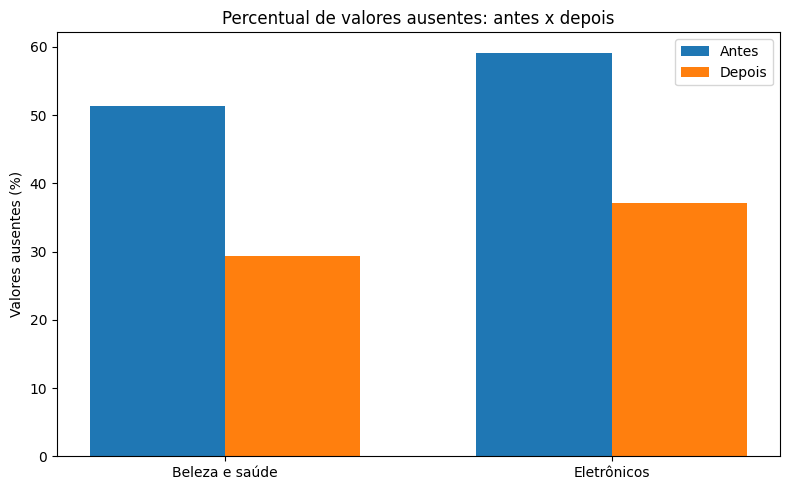

In [27]:
#Visualização
import matplotlib.pyplot as plt

# Dados obtidos na comparação antes x depois
categorias = ["Beleza e saúde", "Eletrônicos"]

# percentual de valores ausentes
antes_ausentes = [51.31, 59.16]
depois_ausentes = [29.28, 37.10]

x = np.arange(len(categorias))
largura = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - largura/2, antes_ausentes, largura, label="Antes")
plt.bar(x + largura/2, depois_ausentes, largura, label="Depois")

plt.xticks(x, categorias)
plt.ylabel("Valores ausentes (%)")
plt.title("Percentual de valores ausentes: antes x depois")
plt.legend()
plt.tight_layout()
plt.show()

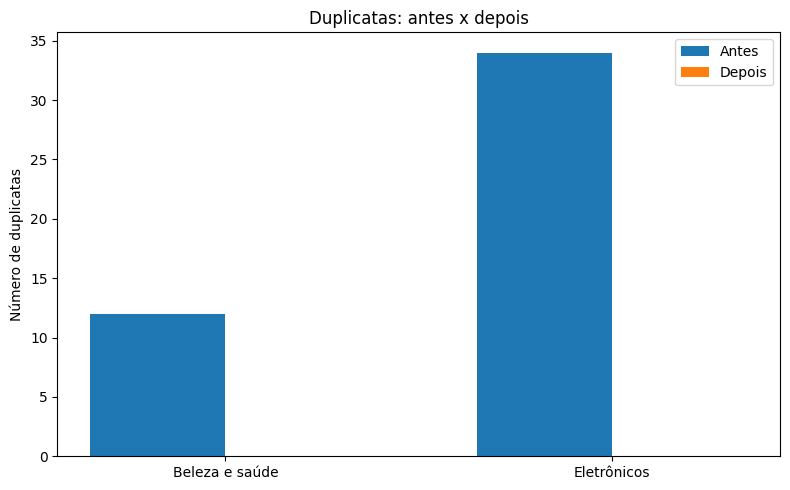

In [28]:
# quantidade de duplicatas
antes_duplicatas = [12, 34]
depois_duplicatas = [0, 0]

plt.figure(figsize=(8, 5))
plt.bar(x - largura/2, antes_duplicatas, largura, label="Antes")
plt.bar(x + largura/2, depois_duplicatas, largura, label="Depois")

plt.xticks(x, categorias)
plt.ylabel("Número de duplicatas")
plt.title("Duplicatas: antes x depois")
plt.legend()
plt.tight_layout()
plt.show()

**Para refletir**

* Qual problema foi o mais difícil de perceber? Por que ele passaria despercebido em uma
análise rápida?

O problema mais difícil de perceber foi a grande quantidade de valores ausentes em algumas colunas. Em uma análise rápida, isso poderia passar despercebido porque os dados ainda aparecem na tabela, mas muitas informações estão incompletas. Isso poderia prejudicar as análises e levar a conclusões incorretas.


* A ordem das etapas importa? Dê um exemplo em que tratar outliers antes dos ausentes (ou vice-versa) mudaria o resultado.

Sim, a ordem importa. Por exemplo, se os valores ausentes da coluna de preço não forem tratados antes da identificação de outliers, alguns cálculos podem apresentar resultados incorretos ou deixar de considerar registros. Por isso, é importante converter os preços para valores numéricos e verificar os dados ausentes antes de calcular os limites para identificar outliers.

* Se a pergunta de negócio fosse outra, qual das suas decisões de limpeza você mudaria?

Se o objetivo fosse analisar as características e a variedade dos produtos, eu evitaria excluir colunas com muitos valores ausentes sem antes avaliar sua importância. Mesmo incompletas, elas poderiam conter informações relevantes. Além disso, manteria os outliers, pois preços muito altos ou baixos podem representar produtos reais e ser importantes para a análise comercial.